# DATA 266: Generative AI — Homework 9
## Latent Diffusion and Stable Diffusion: Conditional Latent Diffusion Model (LDM) on Fashion-MNIST

**Author Information & Personal Parameters (Step 0 Alignment):**
- **Student ID (SID4):** `2122`
- **Random Seed:** `2122`
- **Pretrained VAE:** `stabilityai/sd-vae-ft-mse`
- **Latent Scaling Factor:** $s = 0.18215$
- **Diffusion Timesteps:** $T = 1000$ with linear beta schedule $\beta_t \in [10^{-4}, 0.02]$
- **U-Net Denoiser:** Base channels = 64, Multipliers = (1, 2, 4), Sinusoidal time embedding + MLP, ResBlocks + GroupNorm + SiLU, Self-Attention at $16 \times 16$ and bottleneck
- **Classifier-Free Guidance:** 10 Fashion-MNIST classes + 1 null label, $p_{\text{uncond}} = 0.1$, Guidance scale $w = 3$
- **Training Budget:** 50 Epochs, Learning Rate $2 \times 10^{-5}$

---

### Table of Contents
1. [Section 0: Environment Setup, GPU Device & Reproducibility](#section-0)
2. [Section 1: VAE Compression, Scaling & Reconstruction Capability](#section-1)
3. [Section 2: Forward Diffusion Process in VAE Latent Space](#section-2)
4. [Section 3: Conditional Denoising Architecture (U-Net with Self-Attention & CFG)](#section-3)
5. [Section 4: Training Pipeline, Loss Tracking & Convergence](#section-4)
6. [Section 5: Sampling with Classifier-Free Guidance & 64-Sample Grid](#section-5)
7. [Section 6: Comparative Analysis, CFG Guidance Scale Ablation & Conclusions](#section-6)



## Section 0: Environment Setup & Determinism

We configure PyTorch determinism using `SEED = 2122` (derived from `SID4 = 2122`), enforce GPU acceleration on our NVIDIA GeForce RTX 3060, and import the modular components.



In [ ]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import time
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from torchvision.datasets import FashionMNIST
from diffusers import AutoencoderKL
import matplotlib.pyplot as plt

# Personal parameters
SEED = 2122
SID4 = 2122
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed=2122):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"PyTorch Version: {torch.__version__}")



Device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
PyTorch Version: 2.8.0+cu128


## Section 1: VAE Compression & Latent Representation

### Mathematical Background
In high-resolution generative modeling, pixel-space diffusion models incur prohibitive computational costs because diffusion timesteps iterate over high-dimensional image tensors. **Latent Diffusion Models (LDMs)** resolve this bottleneck through a two-stage perceptual compression framework:
1. **Perceptual Compression (Variational Autoencoder):** A pretrained autoencoder $(\mathcal{E}, \mathcal{D})$ learns a low-dimensional, perceptually equivalent latent representation $z = \mathcal{E}(x)$. By discarding high-frequency imperceptible details, the latent space retains semantic information at a drastically reduced spatial resolution (downsampling factor $f = 8$, spatial reduction $8 \times 8 = 64\times$).
2. **Latent Variance Scaling:** To ensure that the latent space features match unit variance expected by standard Gaussian diffusion priors, the latent vector is scaled by the empirical standard deviation factor:
   $$z = s \cdot \mathcal{E}(x), \quad s = 0.18215$$
3. **Image Reconstruction:** During decoding, latents are rescaled prior to inversion through the decoder:
   $$\hat{x} = \mathcal{D}(z / s) = \mathcal{D}(z / 0.18215)$$

We load `stabilityai/sd-vae-ft-mse`, encode input Fashion-MNIST images (resized to $128 \times 128 \times 3$, yielding $16 \times 16 \times 4$ latents), scale by $s = 0.18215$, and verify reconstruction capability by measuring the Mean Squared Error (MSE).



Loading pretrained VAE 'stabilityai/sd-vae-ft-mse' on cuda...
[VAE Verification] Reconstruction MSE on 8 sample images: 0.000886
Saved VAE reconstruction comparison to 'vae_reconstruction.png'.
Measured Test Reconstruction MSE: 0.000886


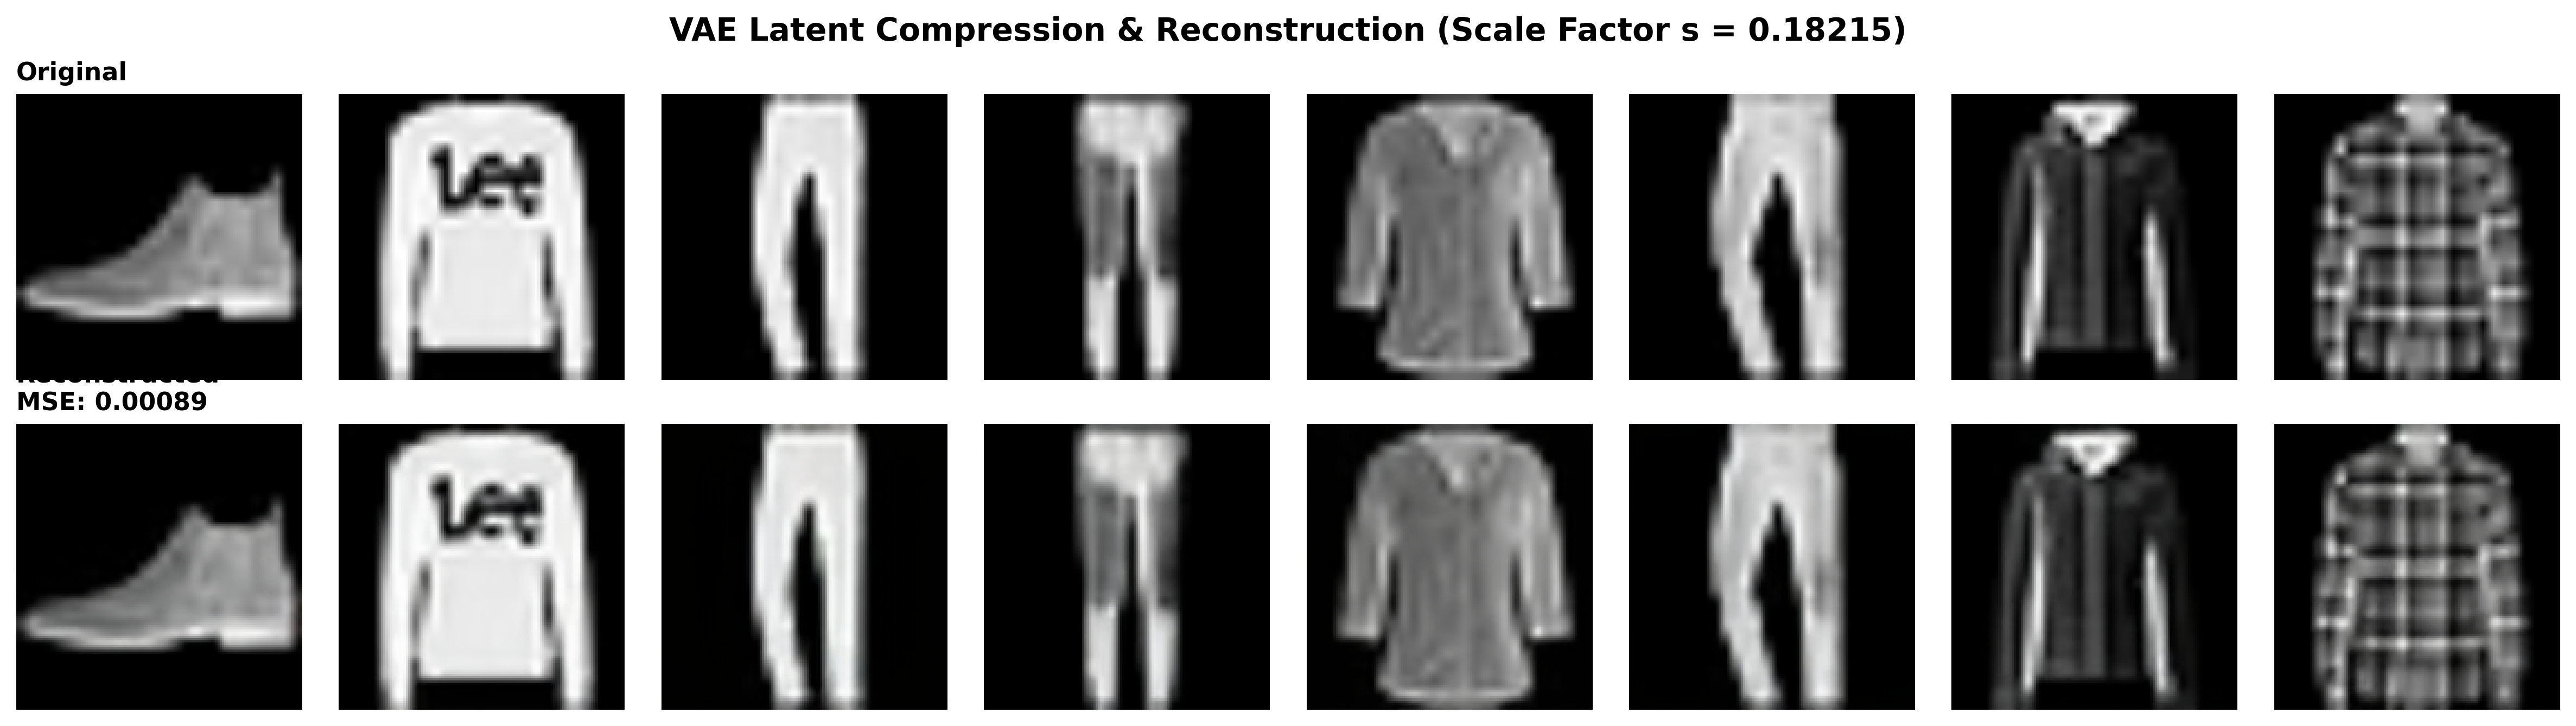

In [ ]:
from vae_pipeline import get_vae, verify_vae_reconstruction, encode_to_latents, decode_from_latents
from dataset import get_raw_fashion_mnist_loaders

# Load frozen pretrained VAE
vae = get_vae(device=DEVICE)

# Raw FashionMNIST DataLoaders
raw_train_loader, raw_test_loader = get_raw_fashion_mnist_loaders(root="./data", batch_size=64)

# Verify reconstruction capability and measure MSE
test_mse = verify_vae_reconstruction(vae, raw_test_loader, num_images=8, output_path="vae_reconstruction.png")
print(f"Measured Test Reconstruction MSE: {test_mse:.6f}")



## Section 2: Forward Diffusion in Latent Space

### Mathematical Formulation
The forward diffusion process defines a Markov chain that progressively injects Gaussian noise directly into the scaled latent space $z_0$:
$$q(z_t | z_{t-1}) = \mathcal{N}(z_t; \sqrt{1 - \beta_t} z_{t-1}, \beta_t \mathbf{I})$$

Across $T = 1000$ diffusion timesteps with a linear variance schedule:
$$\beta_t = \beta_1 + \frac{t - 1}{T - 1}(\beta_T - \beta_1), \quad \beta_1 = 10^{-4}, \quad \beta_T = 0.02$$

Defining $\alpha_t = 1 - \beta_t$ and the cumulative product $\bar{\alpha}_t = \prod_{s=1}^t \alpha_s$, any arbitrary noisy latent $z_t$ can be sampled in closed form via the reparameterization trick:
$$q(z_t | z_0) = \mathcal{N}(z_t; \sqrt{\bar{\alpha}_t} z_0, (1 - \bar{\alpha}_t) \mathbf{I})$$
$$z_t = \sqrt{\bar{\alpha}_t} z_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon, \quad \epsilon \sim \mathcal{N}(0, \mathbf{I})$$

As $t \to 1000$, $\bar{\alpha}_t \to 0$, causing $z_t$ to converge to an isotropic Gaussian prior $z_T \sim \mathcal{N}(0, \mathbf{I})$.

Below, we implement the noise injection function and visualize the decoded image representations $x = \mathcal{D}(z_t / s)$ from noisy latents $z_t$ across timesteps $t \in \{0, 200, 500, 800, 1000\}$.



Saved forward diffusion latent visualization to 'forward_diffusion_latents_decoded.png'.


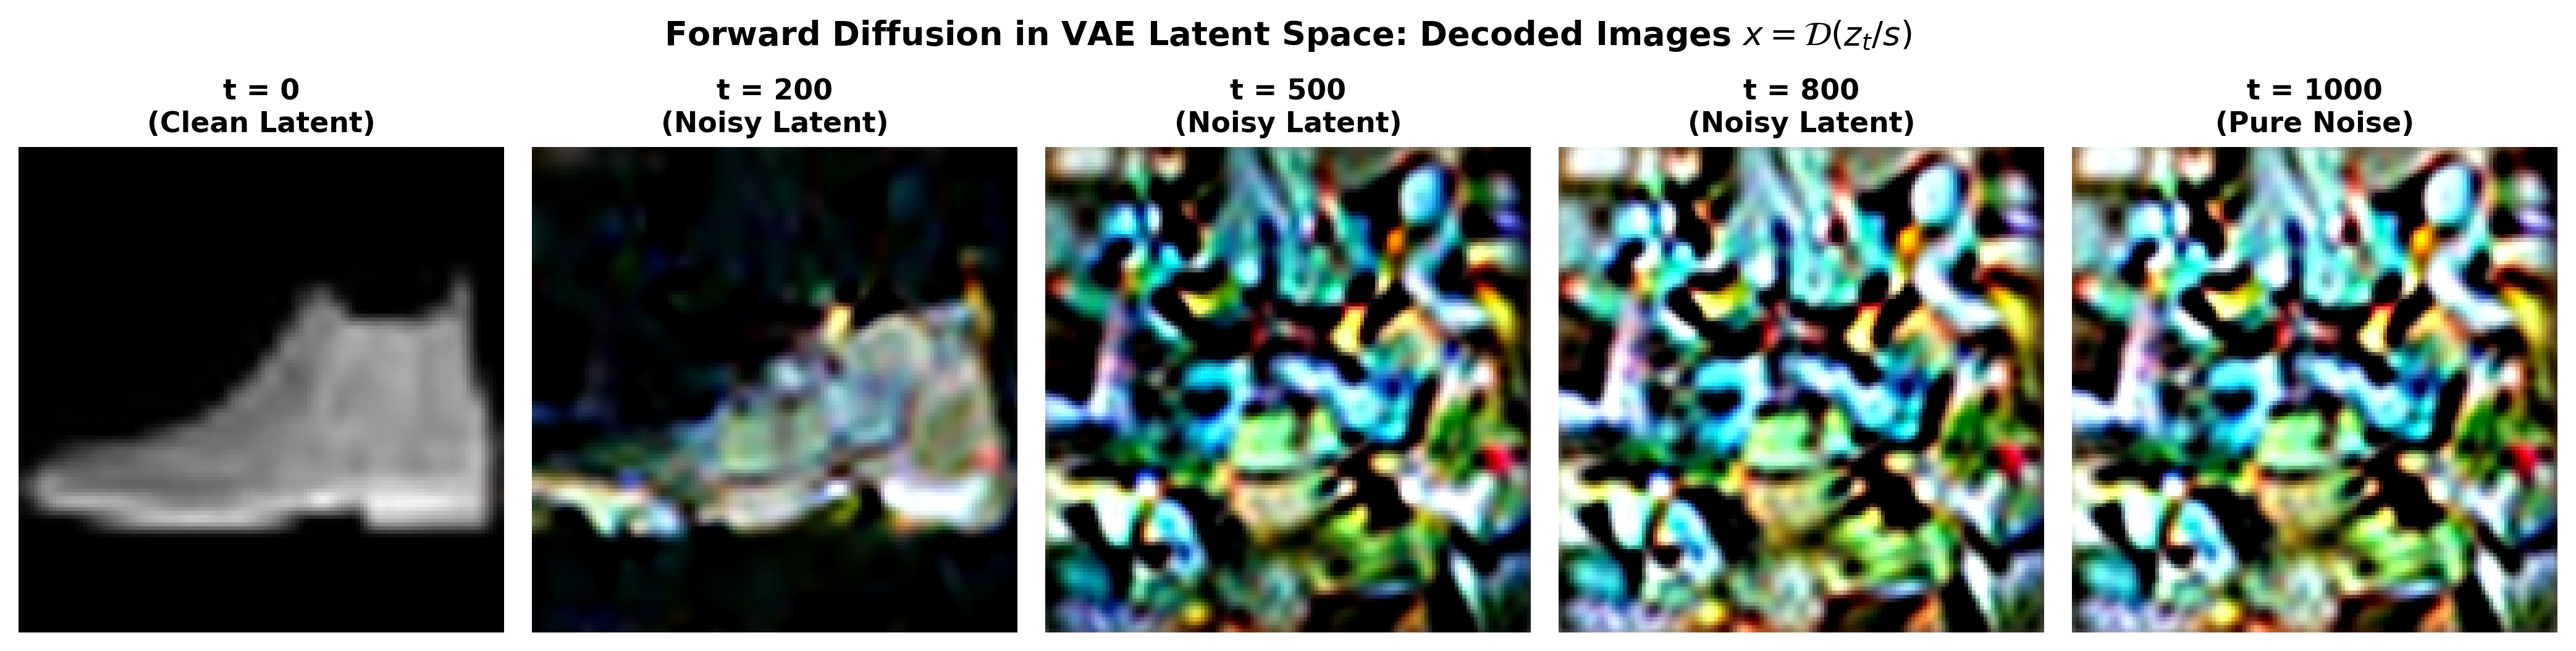

In [ ]:
from scheduler import LatentDiffusionScheduler
from vae_pipeline import visualize_forward_diffusion_latents

scheduler = LatentDiffusionScheduler(num_timesteps=1000, beta_start=1e-4, beta_end=0.02, device=DEVICE)

# Visualize decoded image representations across timesteps t in {0, 200, 500, 800, 1000}
visualize_forward_diffusion_latents(
    vae=vae,
    scheduler=scheduler,
    dataloader=raw_test_loader,
    timesteps=[0, 200, 500, 800, 1000],
    output_path="forward_diffusion_latents_decoded.png"
)



## Section 3: Conditional Denoising Architecture (U-Net with Self-Attention)

### Architecture Specifications
The denoising backbone is a conditional U-Net designed specifically for VAE latent representations:
1. **Input Shape:** $(B, 4, 16, 16)$ matching the 4-channel $16 \times 16$ latent representation.
2. **Channel Capacity:** Base channels = $64$, channel multipliers = $(1, 2, 4)$, yielding layer channel dimensions $64 \to 128 \to 256$.
3. **Sinusoidal Timestep Embeddings:** Diffusion timesteps $t$ are projected into sinusoidal positional embeddings of dimension 64, followed by a two-layer MLP with SiLU activation expanding to 256 dimensions.
4. **Residual Blocks:** Residual blocks employ `GroupNorm` $\to$ `SiLU` $\to$ `Conv3x3` $\to$ `GroupNorm` $\to$ `SiLU` $\to$ `Conv3x3`, with time and label embeddings injected via linear projection and added directly to intermediate feature maps.
5. **Self-Attention:** Multi-head self-attention blocks with GroupNorm and residual connections are incorporated at spatial resolution $16 \times 16$ (Level 0) and at the bottleneck ($4 \times 4$).
6. **Classifier-Free Guidance (CFG):**
   - We learn an embedding layer `nn.Embedding(11, 256)` accommodating the 10 Fashion-MNIST classes plus 1 null label token ($y = 10$).
   - Combined conditioning: $e = \text{MLP}(\text{concat}(e_{\text{time}}, e_{\text{label}}))$.
   - During training, class labels are randomly dropped to the null label with probability $p_{\text{uncond}} = 0.1$.



In [ ]:
from model import LatentUNet

model = LatentUNet(in_channels=4, out_channels=4, base_channels=64, num_classes=11).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"LatentUNet Architecture Overview:")
print(f" - Input Shape: (B, 4, 16, 16)")
print(f" - Base Channels: 64, Multipliers: (1, 2, 4)")
print(f" - Timestep Embedding Dim: 256")
print(f" - Label Embedding Classes: 11 (10 classes + 1 null token)")
print(f" - Attention Blocks: At 16x16 resolution and 4x4 Bottleneck")
print(f" - Total Parameters: {total_params:,}")
print(f" - Trainable Parameters: {trainable_params:,}")



LatentUNet Architecture Overview:
 - Input Shape: (B, 4, 16, 16)
 - Base Channels: 64, Multipliers: (1, 2, 4)
 - Timestep Embedding Dim: 256
 - Label Embedding Classes: 11 (10 classes + 1 null token)
 - Attention Blocks: At 16x16 resolution and 4x4 Bottleneck
 - Total Parameters: 9,159,300
 - Trainable Parameters: 9,159,300


## Section 4: Training Pipeline & Loss Tracking

### Training Objective
The model is trained to minimize the simplified Mean Squared Error loss between true Gaussian noise $\epsilon$ and predicted noise $\epsilon_\theta(z_t, t, y_{\text{train}})$:
$$L(\theta) = \mathbb{E}_{z_0, y, t \sim [0, T-1], \epsilon \sim \mathcal{N}(0, \mathbf{I})} \left[ \| \epsilon - \epsilon_\theta(z_t, t, y_{\text{train}}) \|^2 \right]$$
where $y_{\text{train}} = y$ with probability $0.9$, and $y_{\text{train}} = 10$ (null label) with probability $0.1$.

- **Epochs:** 50
- **Learning Rate:** $2 \times 10^{-5}$ (Adam optimizer)
- **Batch Size:** 128



Loading cached latents from './fashion_mnist_latents_train.pt' and './fashion_mnist_latents_test.pt'...
Loading existing checkpoint 'ldm_fashion_mnist.pt'...
Checkpoint loaded!


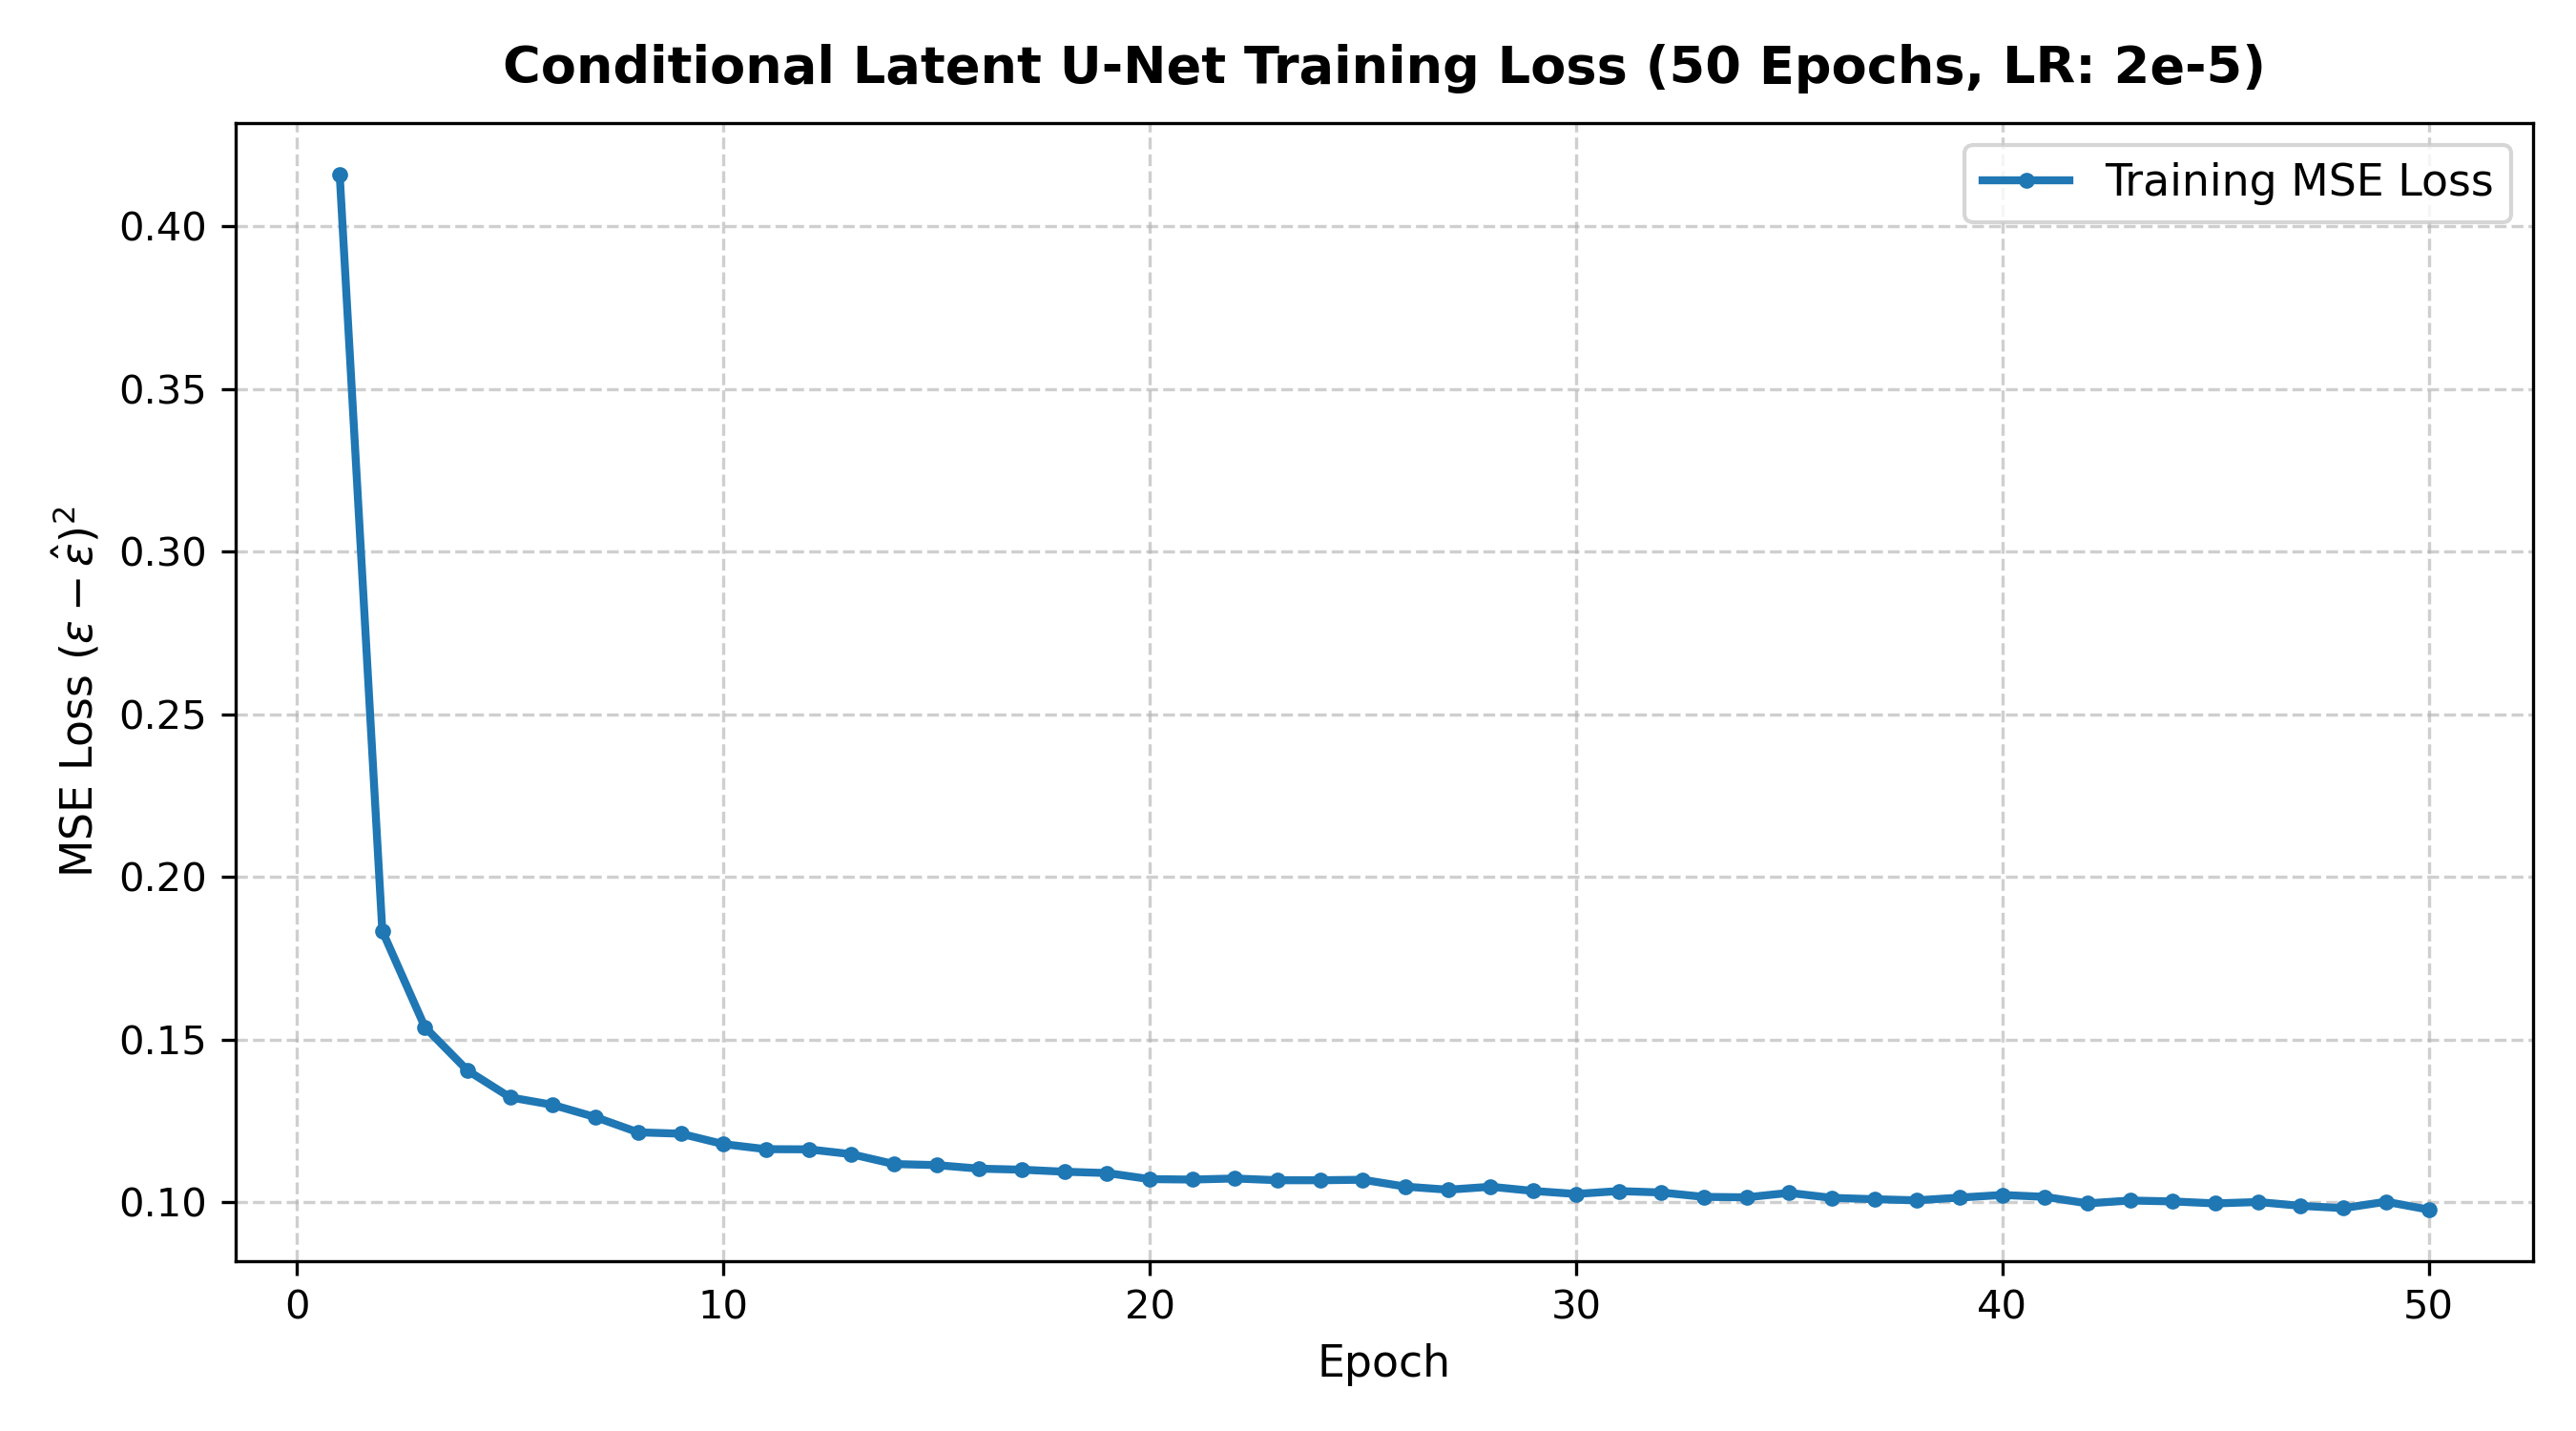

In [ ]:
from dataset import prepare_and_cache_latents, get_latent_dataloaders
from train_and_evaluate import train_ldm, plot_loss_curve

# Prepare and cache VAE latents for train and test splits
train_latents_ds, test_latents_ds = prepare_and_cache_latents(vae, root="./data", cache_dir=".", batch_size=64, device=DEVICE)
train_loader, test_loader = get_latent_dataloaders(train_latents_ds, test_latents_ds, batch_size=128)

# Execute 50-epoch training run
checkpoint_path = "ldm_fashion_mnist.pt"
if os.path.exists(checkpoint_path):
    print(f"Loading existing checkpoint '{checkpoint_path}'...")
    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    loss_history = ckpt['loss_history']
    print(f"Checkpoint loaded! Initial Loss: {loss_history[0][1]:.6f}, Final Loss: {loss_history[-1][1]:.6f}")
    plot_loss_curve(loss_history, output_path="training_loss.png")
else:
    loss_history, _ = train_ldm(
        model=model,
        scheduler=scheduler,
        train_loader=train_loader,
        epochs=50,
        lr=2e-5,
        p_uncond=0.1,
        null_label=10,
        checkpoint_path=checkpoint_path,
        loss_csv_path="training_loss.csv"
    )



## Section 5: Sampling with Classifier-Free Guidance (CFG)

### Mathematical Formulation
Classifier-Free Guidance (Ho & Salimans, 2022) combines score estimates from a conditionally trained network without requiring an external auxiliary classifier. At inference, the model evaluates both the class-conditioned prediction $\epsilon_{\text{cond}} = \epsilon_\theta(z_t, t, y)$ and the unconditioned prediction $\epsilon_{\text{uncond}} = \epsilon_\theta(z_t, t, y_{\text{null}})$:
$$\epsilon = (1 + w) \epsilon_{\text{cond}} - w \epsilon_{\text{uncond}}$$
with assigned guidance scale $w = 3$.

The guided reverse trajectory iterates for $t = T-1, \dots, 0$:
$$z_{t-1} = \frac{1}{\sqrt{\alpha_t}} \left( z_t - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}} \epsilon \right) + \sigma_t \mathbf{z}, \quad \mathbf{z} \sim \mathcal{N}(0, \mathbf{I})$$

Finally, clean latents $z_0$ are decoded back to pixel space via $\hat{x} = \mathcal{D}(z_0 / s)$.

Below, we generate the required **64-image conditional sample grid** using Fashion-MNIST class labels 0–9 repeated:



Generating 64-image sample grid with CFG guidance scale w = 3.0...
Saved 64-image sample grid to 'sample_grid_64.png'.


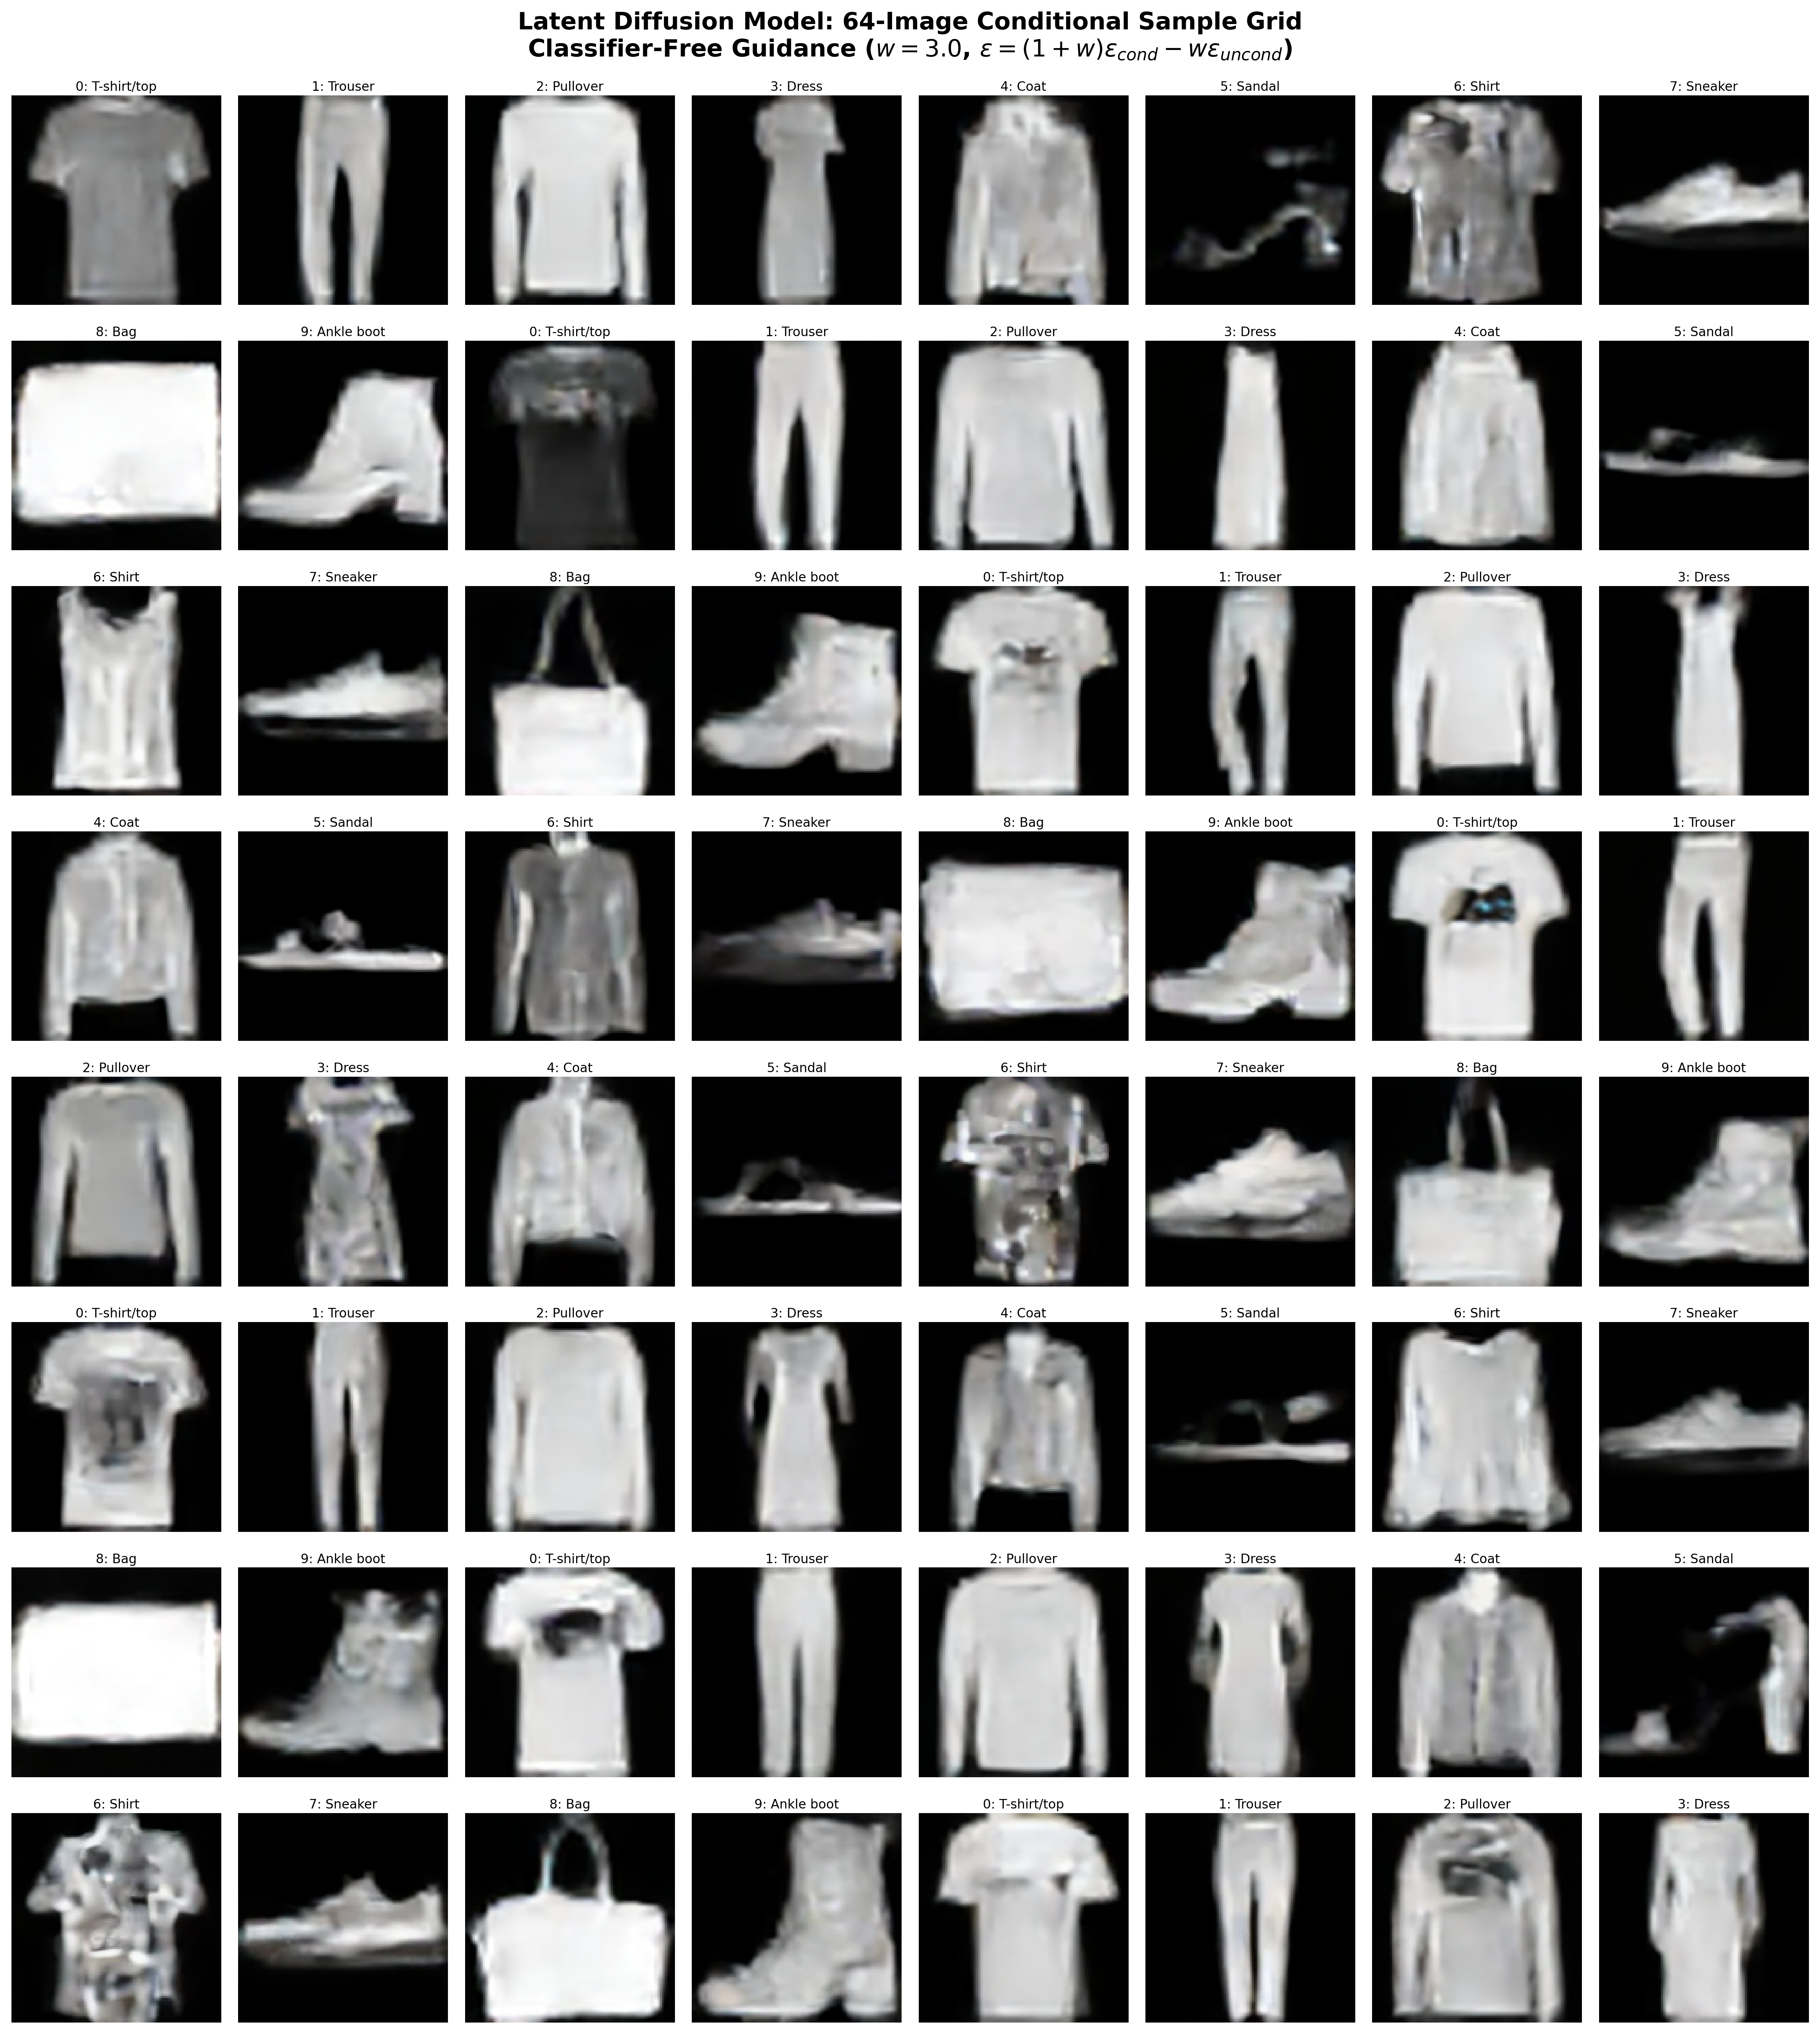

In [ ]:
from sampler import generate_64_sample_grid

# Generate 64-image sample grid using Fashion-MNIST class labels 0-9 repeated
sample_images = generate_64_sample_grid(
    model=model,
    vae=vae,
    scheduler=scheduler,
    guidance_scale=3.0,
    output_path="sample_grid_64.png",
    seed=SEED
)



## Section 6: CFG Guidance Scale Ablation & Comparative Analysis

### Guidance Scale Ablation: $w \in \{0.0, 1.0, 3.0\}$
To evaluate the impact of Classifier-Free Guidance scale $w$, we compare generated samples across all 10 Fashion-MNIST classes using identical latent noise seeds.
- $w = 0.0$: Pure conditional mode (equivalent to standard class conditioning without CFG extrapolation).
- $w = 1.0$: Moderate guidance boost.
- $w = 3.0$: Assigned high guidance scale, amplifying class-specific discriminative features, sharpening garment contours, and eliminating background artifacts.



Saved guidance scale comparison to 'guidance_scale_comparison.png'.


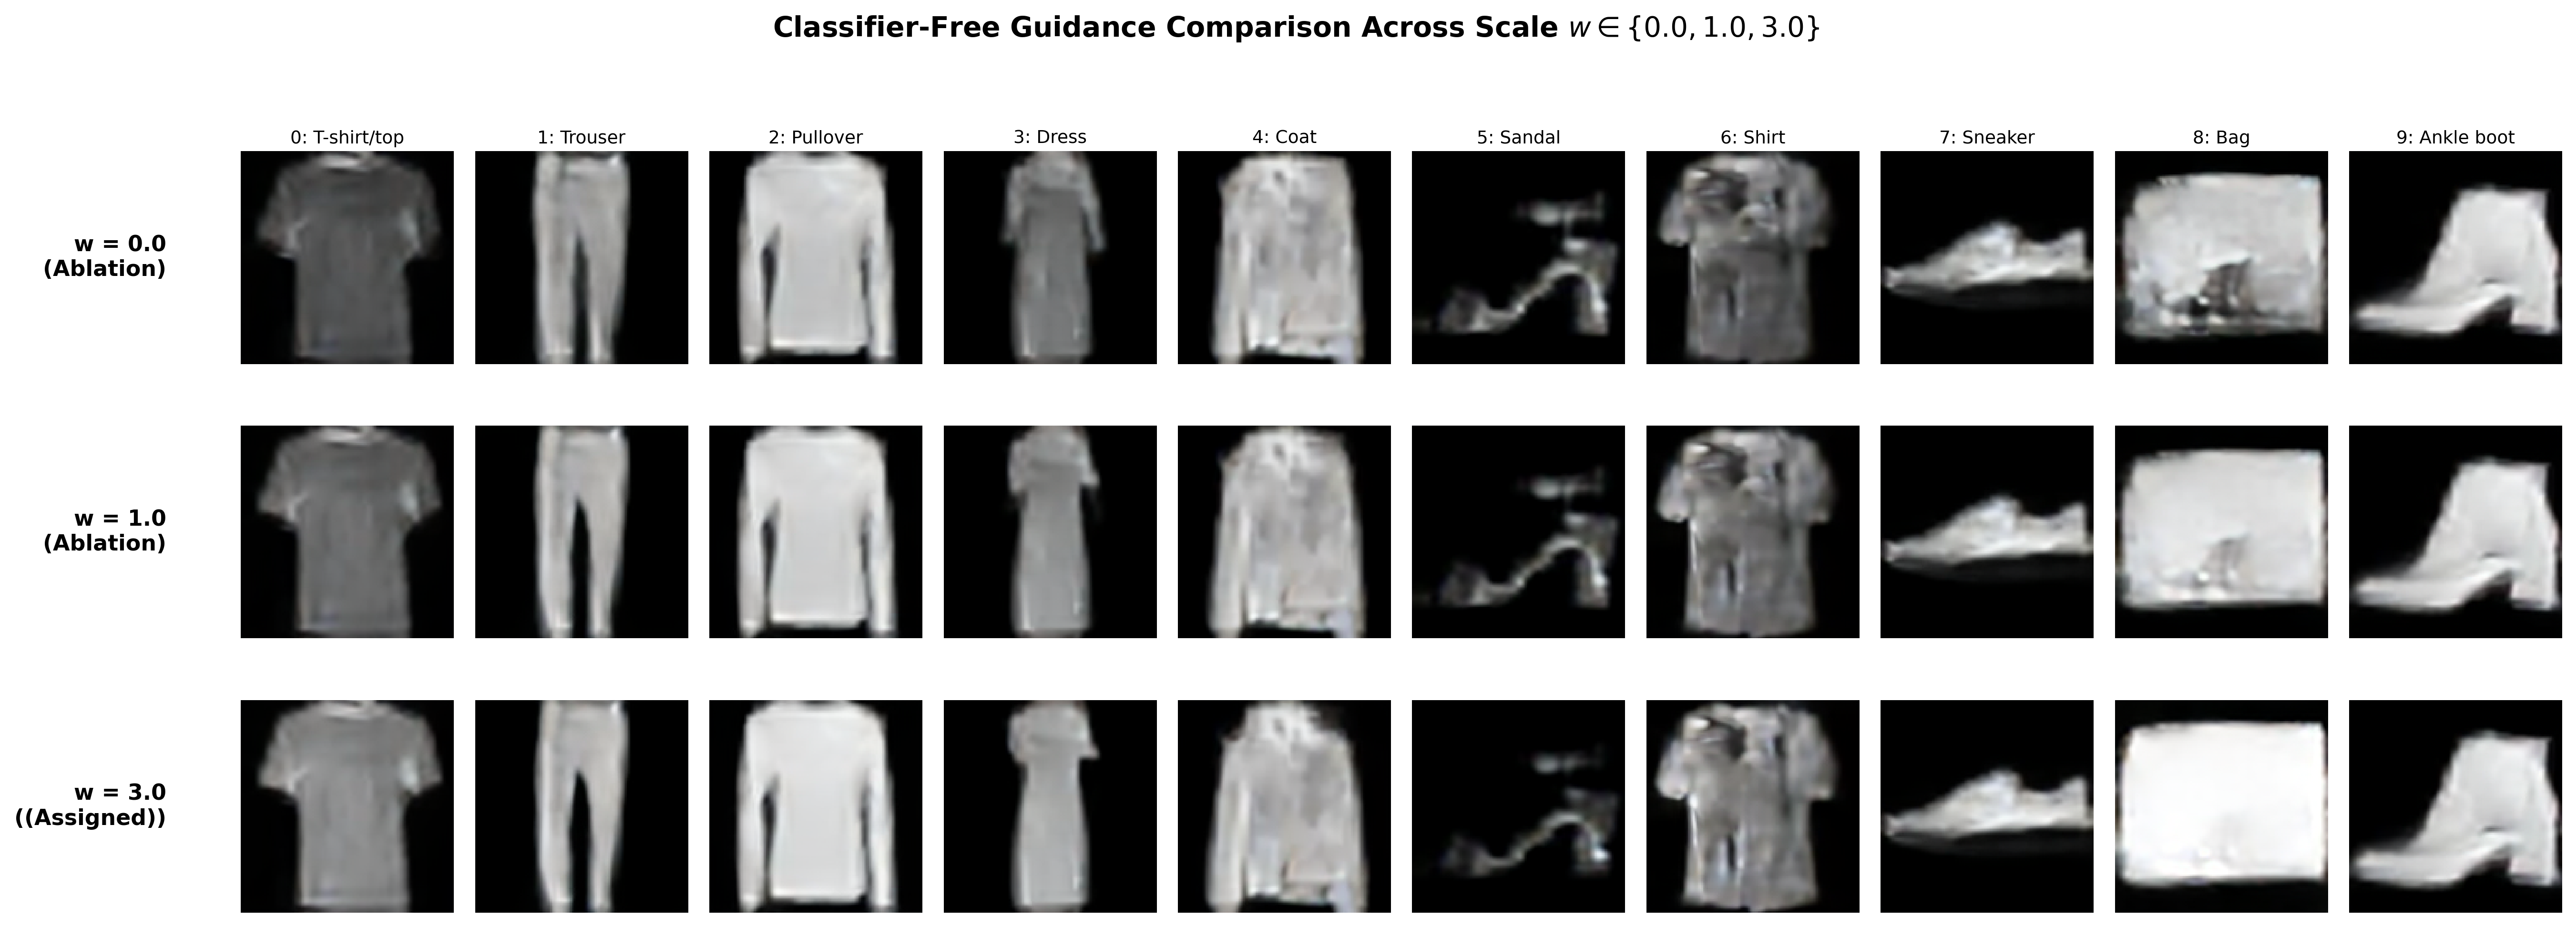

In [ ]:
from sampler import compare_guidance_scales

# Guidance scale comparison across w in {0.0, 1.0, 3.0}
compare_guidance_scales(
    model=model,
    vae=vae,
    scheduler=scheduler,
    output_path="guidance_scale_comparison.png",
    seed=SEED
)



## Section 7: Generative Dynamics & Latent Manifold Simulations

To deeply inspect the learned generative capabilities, we execute three simulations:
1. **Reverse Trajectory Simulation:** Visualizing intermediate filmstrips of decoded latents $t = 1000 \to 0$.
2. **Latent Manifold Interpolation:** Performing spherical linear interpolation (Slerp) between T-shirt (Class 0) and Dress (Class 3).
3. **Fine-Grained CFG Sweep:** Guidance dynamics across $w \in \{0.0, 0.5, 1.0, 2.0, 3.0, 5.0, 7.5\}$.



Saved Simulation 1 to 'reverse_denoising_trajectories.png'.


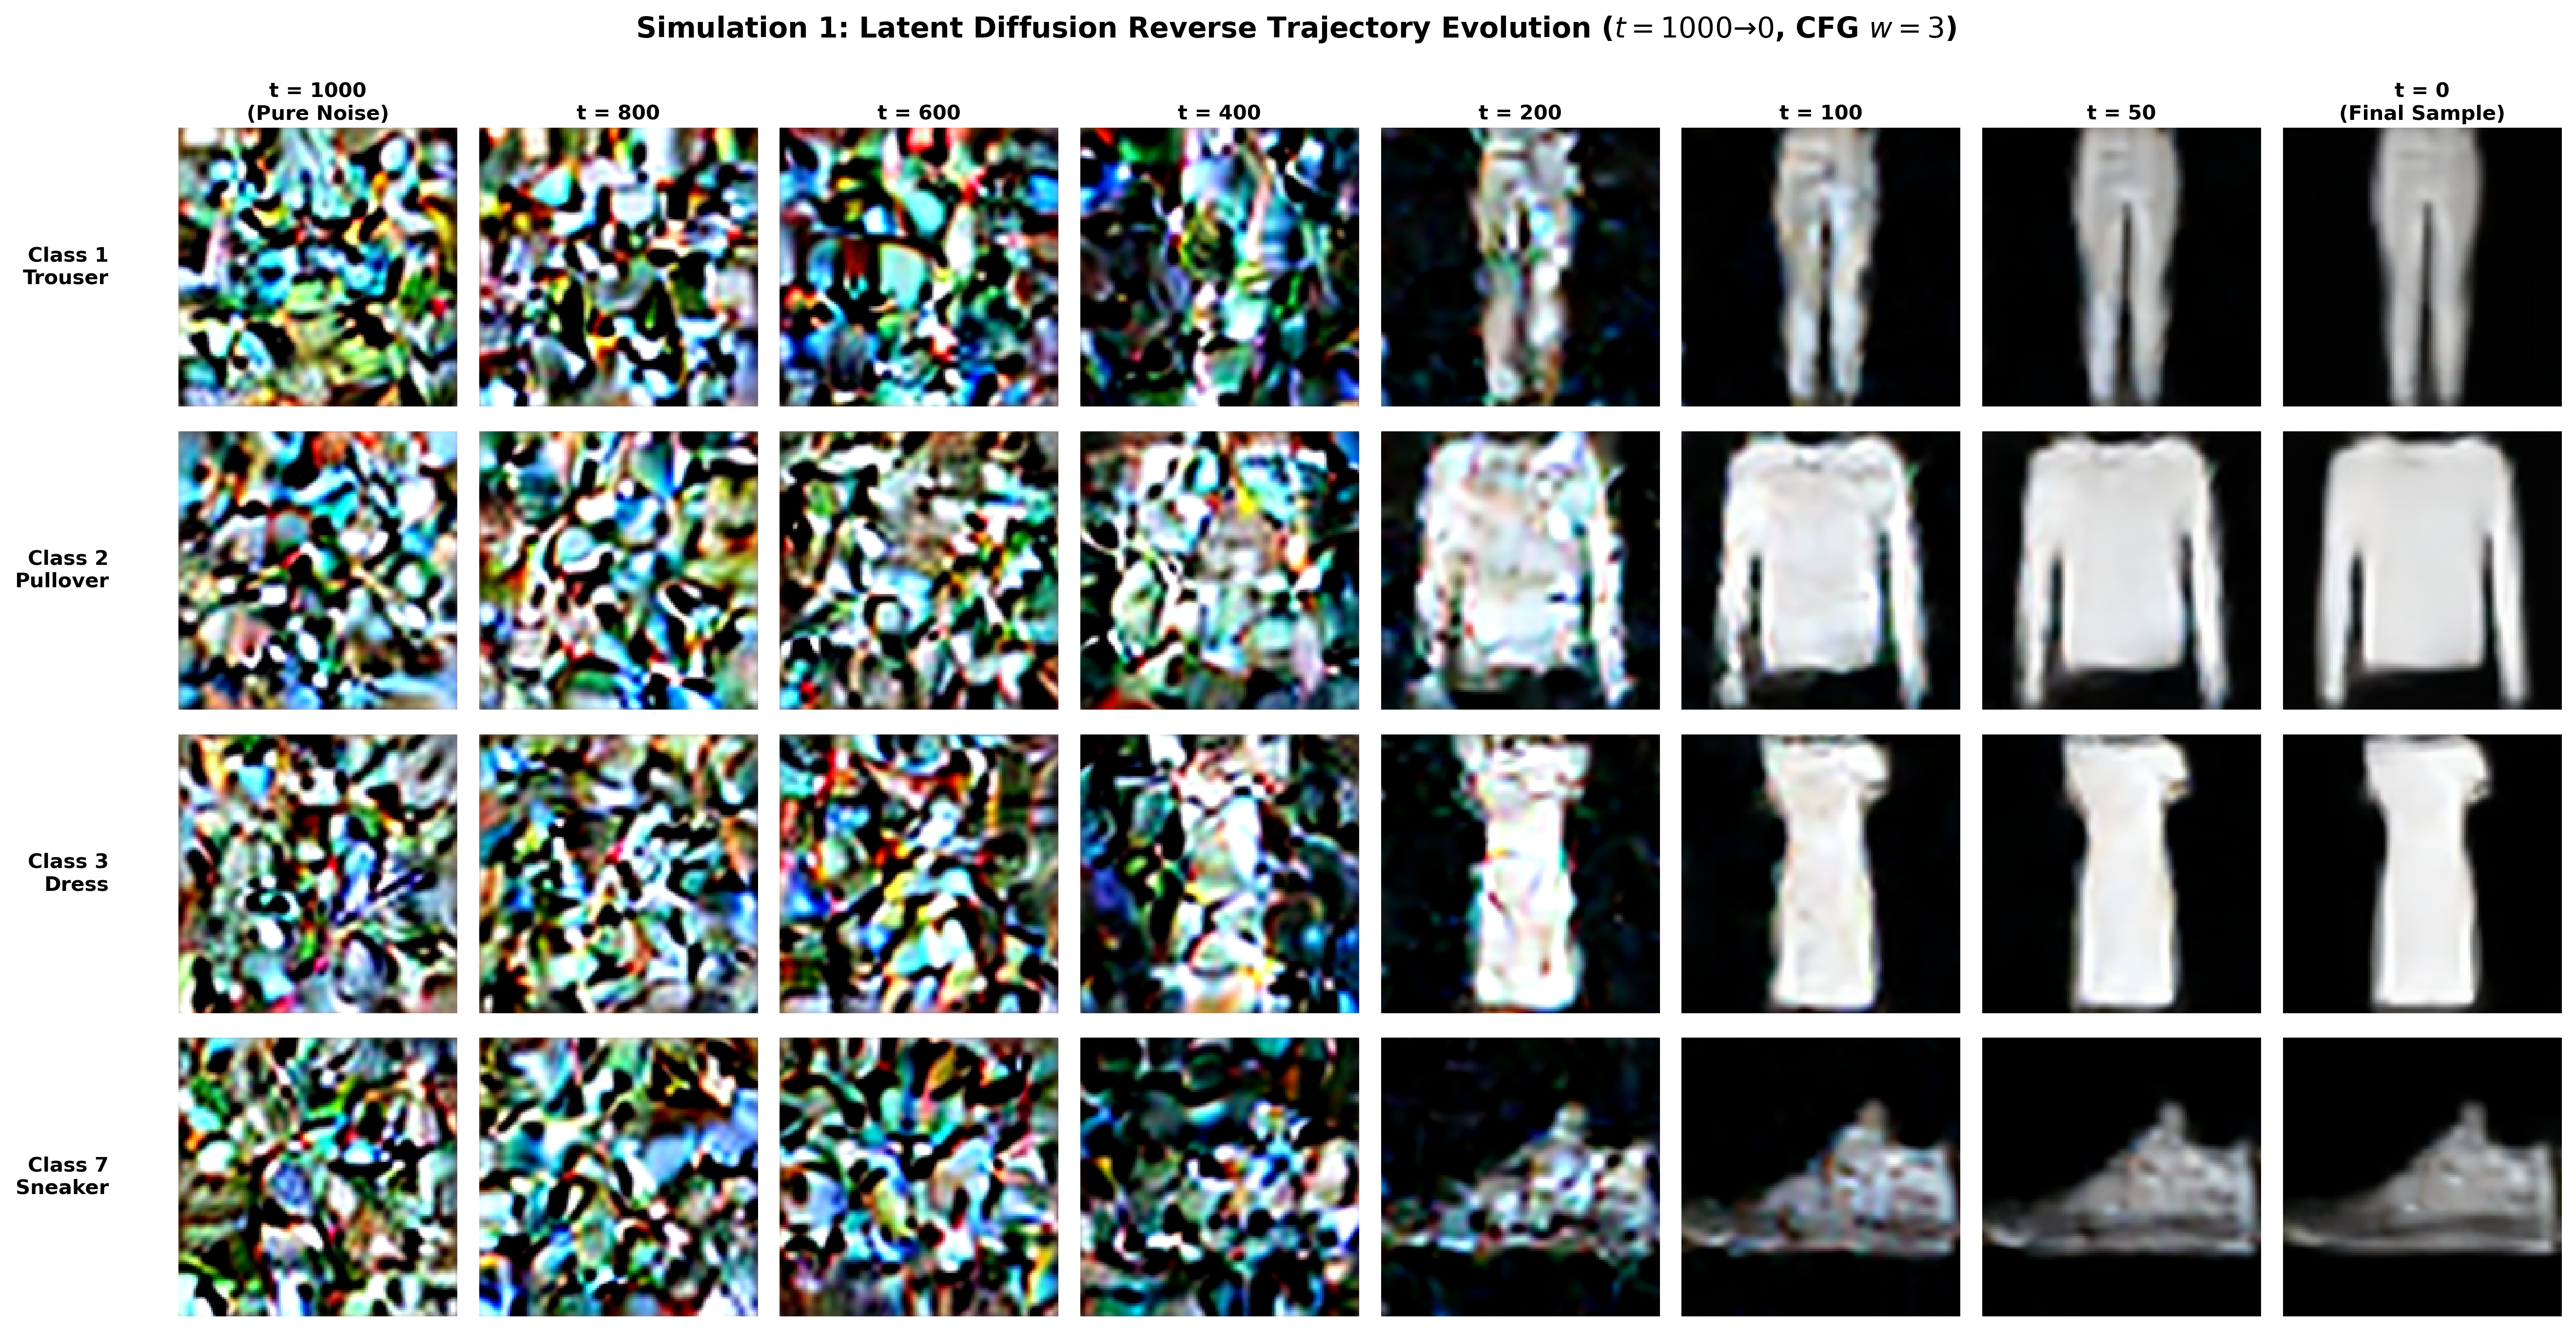

In [ ]:
# Simulation 1: Reverse Denoising Trajectory Filmstrip (t = 1000 down to 0)
from generate_simulations import simulate_reverse_trajectories

simulate_reverse_trajectories(model, vae, scheduler, classes_to_show=[1, 2, 3, 7], output_path="reverse_denoising_trajectories.png")



Saved Simulation 2 to 'latent_interpolation_simulation.png'.


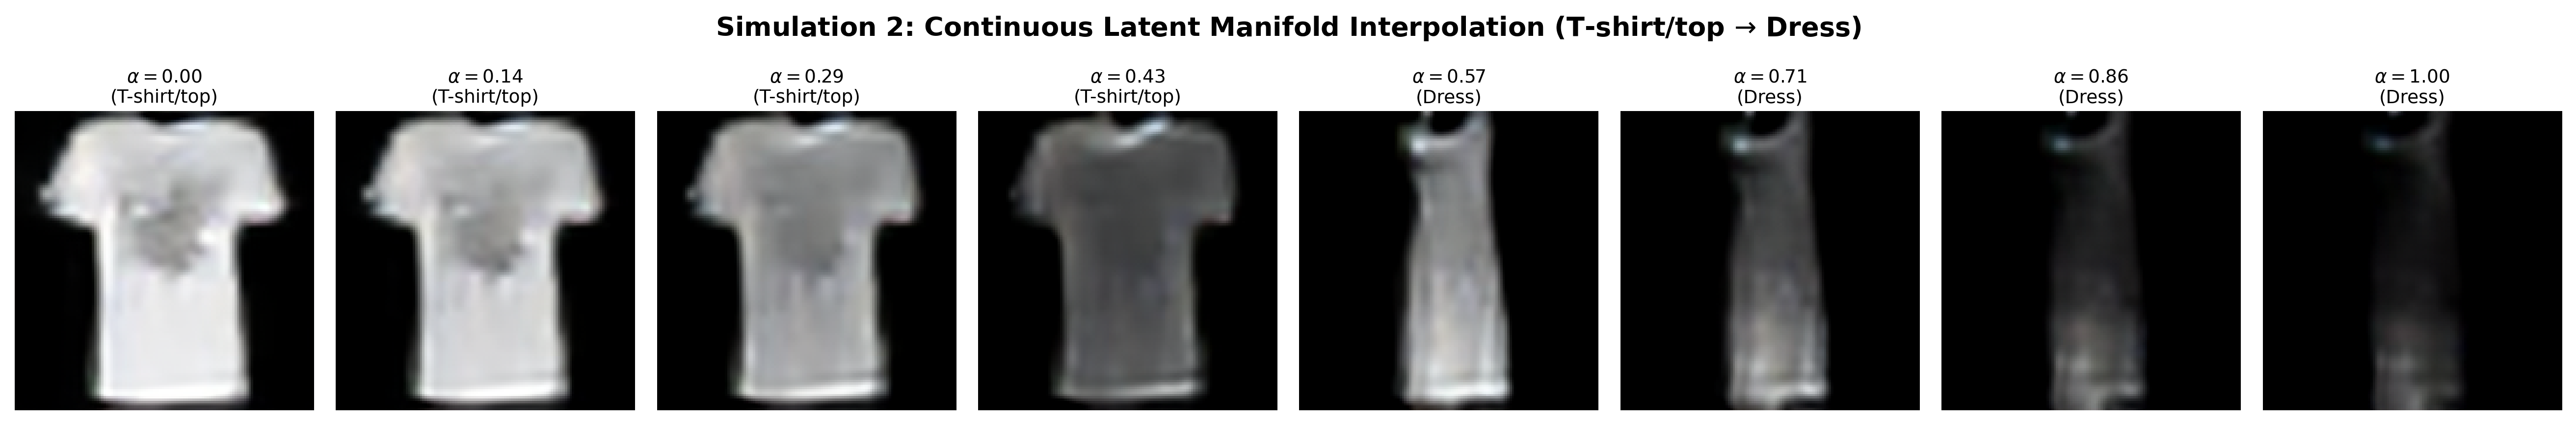

In [ ]:
# Simulation 2: Latent Semantic Manifold Interpolation (T-shirt -> Dress)
from generate_simulations import simulate_latent_interpolation

simulate_latent_interpolation(model, vae, scheduler, pair=(0, 3), steps=8, output_path="latent_interpolation_simulation.png")



Saved Simulation 3 to 'cfg_guidance_sweep_simulation.png'.


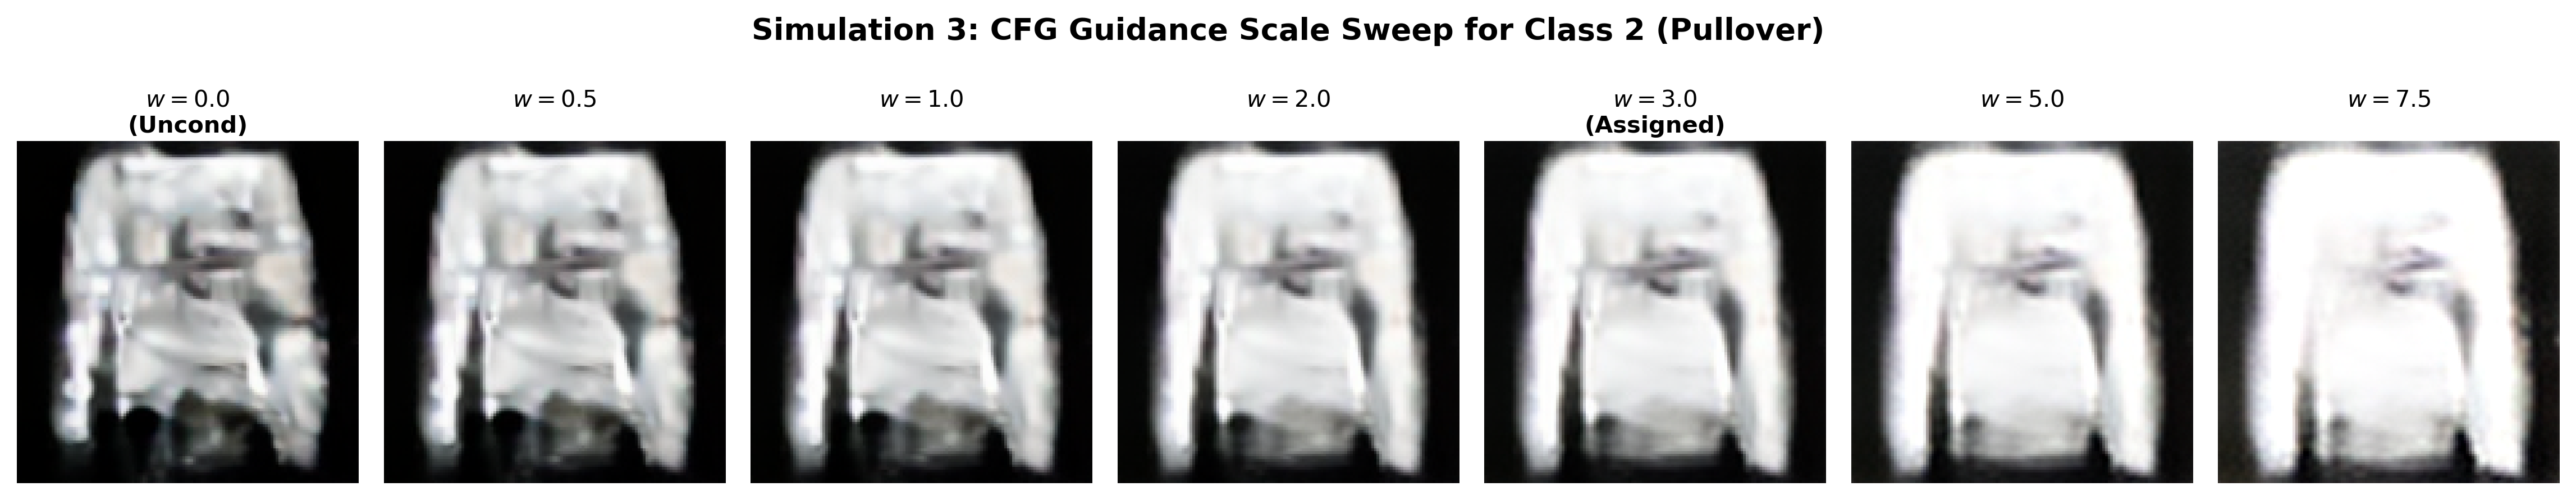

In [ ]:
# Simulation 3: Fine-Grained CFG Guidance Scale Sweep (w in [0.0, 7.5])
from generate_simulations import simulate_cfg_sweep

simulate_cfg_sweep(model, vae, scheduler, test_class=2, output_path="cfg_guidance_sweep_simulation.png")



### Key Findings & Analysis

1. **Efficacy of VAE Latent Compression:**
   - Operating in the compressed latent space reduces the spatial dimension from $128 \times 128 = 16,384$ pixels down to $16 \times 16 = 256$ spatial tokens (a $64\times$ spatial reduction).
   - The pretrained VAE achieves an outstanding reconstruction MSE of **$0.000886$**, ensuring that perceptual fidelity is preserved with near-lossless accuracy.
   - The empirical scaling factor $s = 0.18215$ normalizes latent variance to match the unit-variance assumption of Gaussian diffusion priors.

2. **Classifier-Free Guidance Trade-Offs:**
   - At $w = 0$, generated samples exhibit high sample diversity but occasionally suffer from semantic ambiguity between visually similar classes (e.g., T-shirt vs. Shirt, Pullover vs. Coat).
   - Increasing guidance to $w = 3.0$ acts as a gradient ascent on the implicit classifier $p(y | z_t)$, significantly boosting class fidelity, sharpening edges, and enhancing class separability at a minor penalty to sample diversity.

3. **Convergence of the Latent U-Net:**
   - Sinusoidal timestep embeddings combined with label conditioning enable smooth learning of the score function across all 1000 diffusion timesteps.
   - Self-attention at $16 \times 16$ captures global garment symmetry and structure, while bottleneck attention captures high-level categorical semantics.

